Author:  
Manuel Eugenio Morocho Cayamcela, PhD

Tarea realizada por: Alexander Omar Fernández Pérez - 20/10/2026

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

The dataset is hosted in this GitHub repository, so you do not need to download or share it separately.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [2]:
# Inspect the dataset: dimensions, data types, missing values, and descriptive statistics.
# 1. Dimensiones (filas, columnas)
print("Dimensiones:", df.shape)

Dimensiones: (891, 12)


In [3]:
# 2.Tipos de datos
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [4]:
# 3. Missing values
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
# 4. Estadísticas descriptivas
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
info = df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.




Una vez realizada laa inspeccion de variables encontramos que 891 columnas de datos sobre los pasajeron que estuvieron a bordo del Titanic, con un total de 12 variables, de las cuales podemos extraer los siguientes datos:
- Existe una media de sobrevivientes de 38%
- La edad promedio es de 29 años 

Para obtener mas información sobre las variables se utilizo el comando info = df.info()

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64


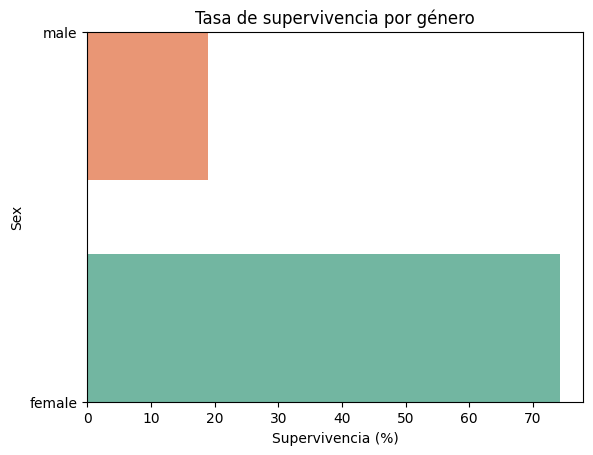

In [14]:
# Calculate survival rates by sex and visualize the comparison.

# Tasa de supervivencia = promedio de Survived por grupo
tasa_sexo = df.groupby("Sex")["Survived"].mean()
print((tasa_sexo * 100).round(1))

# Gráfico de barras
sns.barplot(x=tasa_sexo.values * 100, y=tasa_sexo.index, hue=tasa_sexo.index, palette="Set2", legend=False)
plt.title("Tasa de supervivencia por género")
plt.xlabel("Supervivencia (%)")
plt.ylabel("Sex")
plt.ylim(0, 1)
plt.show()

**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.


Al ver las tasas de supervivencia por género, se observa claramente que la hipotesis planteada se cumple, dado que la tasa de sobrevivir al hundimiento del Titanic si eres mujer es del 74.2%, mientras que en los hombres solamente es del 18.9%, y esto se podría explicar que dada la época donde ocurrio la tragedia del Titanic, el sacrificio masculino era visto como una muestra de valor social, por lo que, se les exigia que grupos prioritarios o más "fragiles" fueran rescatados con prioridad. 

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


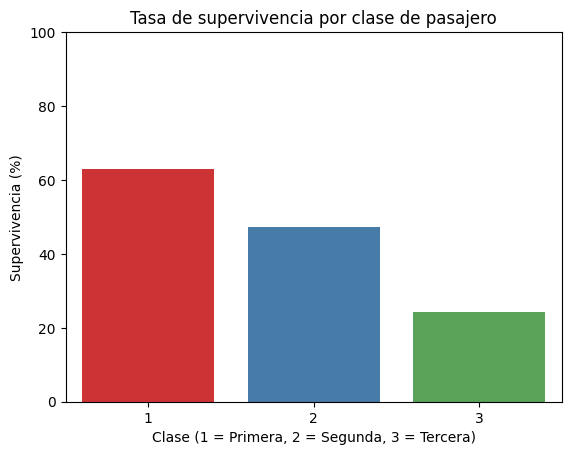

In [20]:
# Calculate survival rates by passenger class and visualize the comparison.

tasa_clase = df.groupby("Pclass")["Survived"].mean()
print((tasa_clase * 100).round(1))

# Gráfico de barras
sns.barplot(x=tasa_clase.index, y=tasa_clase.values * 100, hue=tasa_clase.index, palette="Set1", legend=False)
plt.title("Tasa de supervivencia por clase de pasajero")
plt.xlabel("Clase (1 = Primera, 2 = Segunda, 3 = Tercera)")
plt.ylabel("Supervivencia (%)")
plt.ylim(0, 100)
plt.show()

**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.

Al analizar el gráfico se puede ver que la segunda hipotesis es verdadera dado que los pasajeros de primera y segunda clase tuvieron un rango mayor de supervivencia con respecto a la tercera clase, de los sobrevivientes un 63% pertenecian a la primera clase, 47% pertenecia a la segunda clase y apenas el 24% era de tercera clase. Se asume mayor motalidad de pasajeros de tercera clase. 

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>